<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan2/BTOL/MachineLearningT2_BTVN_Bai3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc: (150, 4)
So lop: 3

TY LE: 80 / 20
Accuracy: 0.9666666666666667
Ma tran nham lan:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


TY LE: 70 / 30
Accuracy: 0.9333333333333333
Ma tran nham lan:
[[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45


TY LE:

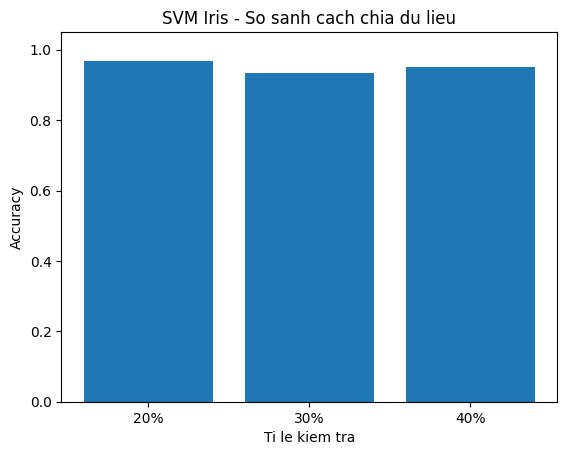

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Nap du lieu
iris = load_iris()
X, y = iris.data, iris.target

print("Kich thuoc:", X.shape)
print("So lop:", len(np.unique(y)))

# 2. Thu 3 cach chia du lieu
results = []

for test_size in [0.2, 0.3, 0.4]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    # 3. Chuan hoa va huan luyen SVM
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1, gamma="scale"))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)

    results.append({
        "Train": len(X_train),
        "Test": len(X_test),
        "Ti le test": int(test_size * 100),
        "Accuracy": accuracy
    })

    print("\nTY LE:", int((1-test_size)*100), "/", int(test_size*100))
    print("Accuracy:", accuracy)
    print("Ma tran nham lan:")
    print(confusion_matrix(y_test, pred))
    print(classification_report(
        y_test, pred,
        target_names=iris.target_names,
        zero_division=0
    ))

# 4. Tong hop ket qua
df = pd.DataFrame(results)
print("\nBANG SO SANH:")
print(df.to_string(index=False))

plt.bar(df["Ti le test"].astype(str) + "%", df["Accuracy"])
plt.ylim(0, 1.05)
plt.xlabel("Ti le kiem tra")
plt.ylabel("Accuracy")
plt.title("SVM Iris - So sanh cach chia du lieu")
plt.show()
